In [1]:
# pretrained models as a check on notebook 04: Chronos-2 on the 'when', TabICLv2 and TabPFN-3.5 on the 'who'. Kernel: Python (yjmob-gpu)
# Every cell saves what it found as it finishes, so after a crash or a session timeout you can rerun cell 0 and carry on from any cell
import os, sys, time, json, getpass
from pathlib import Path
ROOT = Path("/projects/ancz7294/yjmob")
os.environ.setdefault("HF_HOME", str(ROOT.parent / ".cache/huggingface"))       # model weights in /projects, not the small home folder
os.environ.setdefault("TABPFN_MODEL_CACHE_DIR", str(ROOT.parent / ".cache/tabpfn"))
os.environ["TABPFN_NO_BROWSER"] = "1"                                            # a compute node has no browser: the API key stands in for the login
cached = Path.home() / ".cache/tabpfn/auth_token"                                  # where TabPFN keeps the key after its first use
if not os.environ.get("TABPFN_TOKEN") and cached.is_file():
    os.environ["TABPFN_TOKEN"] = cached.read_text().strip()
if not os.environ.get("TABPFN_TOKEN"):
    k = getpass.getpass("Prior Labs API key (hidden; press Enter to skip TabPFN): ").strip()
    if k:                                                                          # asked once: kept where only you can read it
        os.environ["TABPFN_TOKEN"] = k
        cached.parent.mkdir(parents=True, exist_ok=True); cached.write_text(k); cached.chmod(0o600)
    del k
HAVE_KEY = bool(os.environ.get("TABPFN_TOKEN"))
os.environ["TORCH_DISABLE_NATIVE_JIT"] = "1"         # torch 2.14 hands a few ops to Triton kernels that need C headers Alpine lacks; plain PyTorch runs them
import importlib.metadata as md
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, balanced_accuracy_score
PROC, FIG = ROOT / "data/processed", ROOT / "figures"
SEED = 20260917
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
def save(fig, name): fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print("Prior Labs key:", "set (not shown)" if HAVE_KEY else "none, the TabPFN cells will be skipped")
days = pd.read_parquet(PROC / "day_table.parquet").set_index("d").sort_index()
lab = pd.read_parquet(PROC / "person_breaks.parquet")
shares = pd.read_parquet(PROC / "person_day_shares.parquet")
ORDER = ["far roamers", "mid-range movers", "regular commuters", "local regulars", "weekend movers", "homebodies"]
COL = dict(zip(ORDER, [C[0], C[6], C[2], C[3], C[4], C[1]]))                      # the kinds' colours on every tab
print(f"{shares.uid.nunique():,} people x 75 days | label for {len(lab):,} people, {lab.broke.mean():.1%} broke")
# the trees' table: same features, same people, same split as notebook 04
T = pd.read_parquet(PROC / "who_breaks_table.parquet")
feat = [c for c in T.columns if c not in ("broke", "split", "kind")]
tr, te = (T.split == "dev").to_numpy(), (T.split == "eval").to_numpy()
Ftr, Fte = T.loc[tr, feat].reset_index(drop=True), T.loc[te, feat].reset_index(drop=True)      # numbers only, no person ids
Xtr, Xte, ytr, yte = Ftr.to_numpy("float32"), Fte.to_numpy("float32"), T.broke[tr].to_numpy(), T.broke[te].to_numpy()
print(f"who breaks: {len(feat)} features | training {len(Xtr):,} people ({ytr.mean():.1%} broke) | test {len(Xte):,} ({yte.mean():.1%} broke)")
# results so far: the log and each pretrained model's test scores are kept on disk as soon as a cell finishes
LOGF = ROOT / "logs/part3_foundation_log.json"
LOG = json.loads(LOGF.read_text()) if LOGF.exists() else {}
def log_now(**kv):
    LOG.update(kv); LOGF.write_text(json.dumps(LOG, indent=2, default=str))
FM = {"TabICLv2": "tabicl", "TabPFN-3.5": "tabpfn35", "TabPFN-3.5 Thinking": "tabpfn35_thinking"}
FMCOL = {"TabICLv2": C[2], "TabPFN-3.5": C[3], "TabPFN-3.5 Thinking": C[1]}             # one hue family for the two TabPFN settings
P = {}
REFIT = False                     # False: a model whose test scores an earlier run saved is read back, not fitted again (no new API call)
def saved(name):
    fp_ = PROC / f"fm_{FM[name]}_test_scores.parquet"
    if REFIT or not fp_.exists() or FM[name] not in LOG: return False
    P[name] = pd.read_parquet(fp_).p.to_numpy()
    print(f"{name}: test scores from an earlier run ({fp_.name}) | test AUC {LOG[FM[name]]['test_auc']:.3f}"); return True
def keep(name, p, seconds, **extra):
    P[name] = p
    pd.DataFrame({"y": yte, "p": p}).to_parquet(PROC / f"fm_{FM[name]}_test_scores.parquet")
    log_now(**{FM[name]: {"test_auc": round(float(roc_auc_score(yte, p)), 4), "seconds": seconds, "device": DEVICE, **extra}})
def version(p_):
    try: return md.version(p_)
    except md.PackageNotFoundError: return None
log_now(device=DEVICE, gpu=torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
        packages={p_: version(p_) for p_ in ["torch", "chronos-forecasting", "tabicl", "tabpfn", "tabpfn-client", "scikit-learn"]})

torch 2.14.1+cu126 | device: cuda NVIDIA L40
Prior Labs key: set (not shown)
24,514 people x 75 days | label for 23,904 people, 19.1% broke
who breaks: 34 features | training 16,769 people (19.2% broke) | test 7,135 (18.9% broke)


/projects/ancz7294/software/uv/envs/yjmob-gpu/lib64/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 170/170 [00:00<00:00, 3051.87it/s]


Chronos-2: 23,904 people, 1,434,240 forecasts in 22 s on cuda
day level, evaluation people: AUC of the forecast loss for emergency vs ordinary days 0.601
emergency fortnight forecast worse for 0.679 of evaluation people
agreement with the habit-model label (evaluation people): correlation with the rise in surprise 0.502, AUC of the Chronos score for 'broke' 0.777
kind
far roamers          0.0018
mid-range movers     0.0041
regular commuters    0.0132
local regulars       0.0083
weekend movers       0.0089
homebodies           0.0018
multinomial NB              0.538
Bernoulli NB (when seen)    0.591
where NB, everyone          0.532
where NB, per kind          0.548
where NB, per person        0.559
Chronos-2, zero-shot        0.601


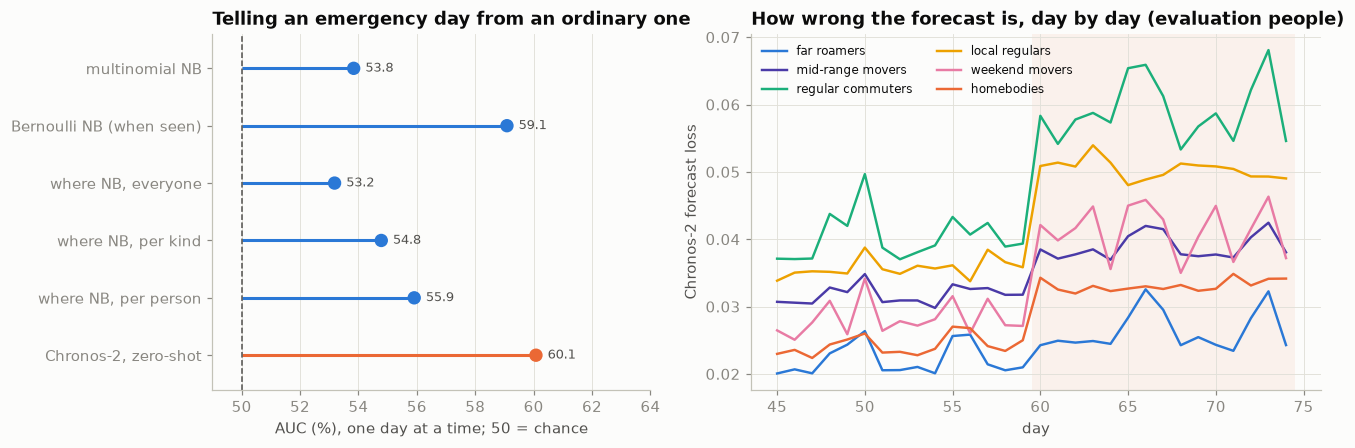

/projects/ancz7294/software/uv/envs/yjmob-gpu/lib64/python3.11/site-packages/pandas/io/parquet.py:191: UserWarning: The DataFrame has column names of mixed type. They will be converted to strings and not roundtrip correctly.
  table = self.api.Table.from_pandas(df, **from_pandas_kwargs)


In [2]:
# Chronos-2 (Amazon, Apache-2.0), zero-shot: from each person's own history it forecasts two daily numbers, the share of seen half
# hours at home and at the daytime place. Two forecasts of 15 days each, made from days 0-44 and from days 0-59, so the ordinary and the
# emergency fortnight are forecast from the same distance. A day the forecast misses badly is a day the routine did not follow its past.
from chronos import Chronos2Pipeline
s = shares.copy()
s["home"] = np.where(s.seen >= 4, s.home / s.seen.clip(lower=1), np.nan); s["place"] = np.where(s.seen >= 4, s.place / s.seen.clip(lower=1), np.nan)
ts = pd.date_range("2000-01-01", periods=75, freq="D")                          # only an index: the data has no calendar
s["timestamp"] = ts[s.d.to_numpy()]
s["workday"] = days.workday.reindex(s.d).to_numpy().astype(float); s["weekend"] = days.weekend.reindex(s.d).to_numpy().astype(float)
s = s[s.uid.isin(lab.index)].rename(columns={"uid": "id"})[["id", "timestamp", "home", "place", "workday", "weekend"]]
pipe = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE)
t0, out = time.time(), []
for origin in [44, 59]:
    ctx = s[s.timestamp <= ts[origin]]
    fut = s[(s.timestamp > ts[origin]) & (s.timestamp <= ts[origin + 15])][["id", "timestamp", "workday", "weekend"]]
    out.append(pipe.predict_df(ctx, future_df=fut, id_column="id", timestamp_column="timestamp", target=["home", "place"],
                               prediction_length=15, quantile_levels=[0.1, 0.5, 0.9], batch_size=256))
pr = pd.concat(out)
secs = round(time.time() - t0, 1)
print(f"Chronos-2: {pr.id.nunique():,} people, {len(pr):,} forecasts in {secs:.0f} s on {DEVICE}")
act = s.set_index(["id", "timestamp"])[["home", "place"]].stack().rename("y").reset_index().rename(columns={"level_2": "target_name"})
m = pr.merge(act, on=["id", "timestamp", "target_name"], how="inner")
m["loss"] = sum(np.maximum(q * (m.y - m[str(q)]), (q - 1) * (m.y - m[str(q)])) for q in [0.1, 0.5, 0.9]) / 3   # quantile loss
m["d"] = (m.timestamp - ts[0]).dt.days
dl = m.groupby(["id", "d"]).loss.mean().reset_index(); dl["y"] = (dl.d >= 60).astype(int)
dl["split"] = lab.split.reindex(dl.id).to_numpy(); dl["kind"] = lab.kind.reindex(dl.id).to_numpy()
ev = dl[dl.split == "eval"]
print(f"day level, evaluation people: AUC of the forecast loss for emergency vs ordinary days {roc_auc_score(ev.y, ev.loss):.3f}")
per = dl.groupby(["id", "y"]).loss.mean().unstack().dropna(); per["chronos_score"] = per[1] - per[0]
per = per.join(lab[["broke", "delta", "kind", "split"]])
pe_ = per[per.split == "eval"]
print(f"emergency fortnight forecast worse for {np.mean(pe_.chronos_score > 0):.3f} of evaluation people")
print(f"agreement with the habit-model label (evaluation people): correlation with the rise in surprise {np.corrcoef(pe_.chronos_score, pe_.delta)[0, 1]:.3f},"
      f" AUC of the Chronos score for 'broke' {roc_auc_score(pe_.broke, pe_.chronos_score):.3f}")
print(pe_.groupby("kind").chronos_score.median().reindex(ORDER).round(4).to_string())
nb = pd.read_csv(PROC / "nb_detectors_eval.csv"); nbm = pd.read_csv(PROC / "nb_models_eval.csv", index_col=0)
auc = pd.Series({"multinomial NB": nbm.loc["multinomial (where and when)", "AUC"], "Bernoulli NB (when seen)": nbm.loc["Bernoulli (when seen)", "AUC"],
                 "where NB, everyone": nb[(nb.kind == "all") & (nb.detector == "one for everyone")].AUC.iloc[0],
                 "where NB, per kind": nb[(nb.kind == "all") & (nb.detector == "one per kind")].AUC.iloc[0],
                 "where NB, per person": nb[(nb.kind == "all") & (nb.detector == "one per person")].AUC.iloc[0],
                 "Chronos-2, zero-shot": roc_auc_score(ev.y, ev.loss)})
print(auc.round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
yy = np.arange(len(auc))[::-1]; col = [C[1] if "Chronos" in i else C[0] for i in auc.index]
axes[0].hlines(yy, 50, auc.values * 100, colors=col, lw=2); axes[0].scatter(auc.values * 100, yy, color=col, s=60, zorder=3)
for v, y_ in zip(auc.values, yy): axes[0].text(v * 100 + 0.4, y_, f"{v * 100:.1f}", va="center", fontsize=8.5, color="#52514e")
axes[0].axvline(50, color="#52514e", ls="--", lw=1); axes[0].set_yticks(yy); axes[0].set_yticklabels(auc.index); axes[0].yaxis.grid(False)
axes[0].set(xlim=(49, max(64, auc.max() * 100 + 3)), ylim=(-0.6, len(auc) - 0.4), xlabel="AUC (%), one day at a time; 50 = chance",
            title="Telling an emergency day from an ordinary one")
for k in ORDER:
    g = ev[ev.kind == k].groupby("d").loss.mean(); axes[1].plot(g.index, g.values, lw=1.6, color=COL[k], label=k)
axes[1].axvspan(59.5, 74.5, color=C[1], alpha=0.07, lw=0)
axes[1].set(xlabel="day", ylabel="Chronos-2 forecast loss", title="How wrong the forecast is, day by day (evaluation people)"); axes[1].legend(frameon=False, fontsize=8, ncol=2)
save(fig, "f45_chronos")
per.to_parquet(PROC / "chronos_scores.parquet")
log_now(chronos={"seconds": secs, "day_auc_eval": round(float(auc["Chronos-2, zero-shot"]), 4),
                 "worse_in_emergency_share": round(float(np.mean(pe_.chronos_score > 0)), 4),
                 "corr_with_surprise_rise": round(float(np.corrcoef(pe_.chronos_score, pe_.delta)[0, 1]), 4),
                 "agrees_with_label_auc": round(float(roc_auc_score(pe_.broke, pe_.chronos_score)), 4),
                 "median_score_by_kind": pe_.groupby("kind").chronos_score.median().reindex(ORDER).round(5).to_dict(),
                 "nb_and_chronos_day_auc": auc.round(4).to_dict()})

In [3]:
# TabICLv2 (Feb 2026, BSD licence, open weights): a transformer pretrained on millions of synthetic tables. It reads the training
# people as examples and predicts the test people in one pass, with no training on our data. Same features, same people as the trees
from tabicl import TabICLClassifier
if not saved("TabICLv2"):
    t0 = time.time()
    icl = TabICLClassifier(device=DEVICE, random_state=SEED).fit(Xtr, ytr)
    keep("TabICLv2", icl.predict_proba(Xte)[:, 1], round(time.time() - t0, 1))
    print(f"TabICLv2: {len(Xtr):,} training people read as examples, {len(Xte):,} predicted in {LOG['tabicl']['seconds']:.0f} s on {DEVICE}"
          f" | test AUC {LOG['tabicl']['test_auc']:.3f}")

TabICLv2: test scores from an earlier run (fm_tabicl_test_scores.parquet) | test AUC 0.662


In [4]:
# TabPFN-3.5 (Prior Labs, Sept 2026; weights free for research under the TabPFN-3.5 licence): the same idea as TabICLv2, the newest
# and largest open model of its family. 32 ensemble members instead of the default 8: each reads a differently shuffled and transformed
# copy of the table, and their predictions are averaged. On the GPU it runs here; without a GPU the same model runs on Prior Labs' servers
if saved("TabPFN-3.5"): pass
elif not HAVE_KEY: print("TabPFN-3.5 skipped: no Prior Labs key (cell 0)")
else:
    try:
        t0 = time.time()
        if DEVICE == "cuda":
            from tabpfn import TabPFNClassifier
            from tabpfn.constants import ModelVersion
            pfn = TabPFNClassifier.create_default_for_version(ModelVersion.V3_5, device=DEVICE, n_estimators=32, random_state=SEED,
                                                               ignore_pretraining_limits=True)
            pfn.fit(Xtr, ytr)
            p_, cfg = pfn.predict_proba(Xte)[:, 1], pfn.inference_config_
            where = {"where": "local GPU", "pretraining_max_rows": int(cfg.MAX_NUMBER_OF_SAMPLES), "pretraining_max_columns": int(cfg.MAX_NUMBER_OF_FEATURES)}
        else:                                                                      # no GPU in this session: the same model on Prior Labs' GPUs
            import tabpfn_client
            from tabpfn_client import TabPFNClassifier as CloudTabPFN
            tabpfn_client.set_access_token(os.environ["TABPFN_TOKEN"])
            pfn = CloudTabPFN.create_default_for_version("v3.5", n_estimators=32, random_state=SEED)
            pfn.fit(Ftr, ytr)
            p_ = pfn.predict_proba(Fte)[:, 1]
            where = {"where": "Prior Labs API", "model_path": "v3.5_default"}
        keep("TabPFN-3.5", p_, round(time.time() - t0, 1), n_estimators=32, **where)
        r = LOG["tabpfn35"]
        print(f"TabPFN-3.5 ({r['where']}): {len(Xtr):,} training people read as examples, {len(Xte):,} predicted in {r['seconds']:.0f} s"
              f" | test AUC {r['test_auc']:.3f}")
        if "pretraining_max_rows" in r:
            print(f"pretrained for tables of up to {r['pretraining_max_rows']:,} rows and {r['pretraining_max_columns']} columns; this one has {len(Xtr):,} and {Xtr.shape[1]}")
    except Exception as e:
        print(f"TabPFN-3.5 skipped: {type(e).__name__}: {str(e)[:1500]}")

TabPFN-3.5: test scores from an earlier run (fm_tabpfn35_test_scores.parquet) | test AUC 0.664


In [5]:
# TabPFN-3.5 Thinking, Prior Labs' strongest setting, which runs only on their servers. At fit time it spends extra compute searching
# over preprocessing and ensembles with internal validation, here told to maximise AUC. The table goes to Prior Labs without person ids.
# It needs no GPU: in a short GPU session, run cell 0 and then this cell from the CPU session instead
THINK_EFFORT, THINK_SECONDS = "high", 2400                                         # the most the API allows: 'high' effort, 40 minutes
if saved("TabPFN-3.5 Thinking"): pass
elif not HAVE_KEY: print("TabPFN-3.5 Thinking skipped: no Prior Labs key (cell 0)")
else:
    try:
        import tabpfn_client
        from tabpfn_client import TabPFNClassifier as CloudTabPFN
        tabpfn_client.set_access_token(os.environ["TABPFN_TOKEN"])
        info = {"effort": THINK_EFFORT, "budget_s": THINK_SECONDS, "metric": "roc_auc", "usage_before": tabpfn_client.get_api_usage()}
        print(info["usage_before"])
        try:
            q = tabpfn_client.estimate_cost(Ftr, operation="thinking_fit", thinking_effort=THINK_EFFORT)
            info["quote_fit"] = {"cost": q.estimated_cost, "pricing": q.pricing_version}; print("quote for the thinking fit:", info["quote_fit"])
        except Exception as e:
            print("no quote:", type(e).__name__, str(e)[:300])
        t0 = time.time()
        think = CloudTabPFN(thinking_effort=THINK_EFFORT, thinking_metric="roc_auc", thinking_timeout_s=THINK_SECONDS, random_state=SEED)
        think.fit(Ftr, ytr)
        p_ = think.predict_proba(Fte)[:, 1]
        info["usage_after"] = tabpfn_client.get_api_usage(); print(info["usage_after"])
        keep("TabPFN-3.5 Thinking", p_, round(time.time() - t0, 1), **info)
        print(f"TabPFN-3.5 Thinking: fit and prediction in {LOG['tabpfn35_thinking']['seconds']:.0f} s on Prior Labs' servers"
              f" | test AUC {LOG['tabpfn35_thinking']['test_auc']:.3f}")
    except Exception as e:
        print(f"TabPFN-3.5 Thinking skipped: {type(e).__name__}: {str(e)[:1500]}")

TabPFN-3.5 Thinking: test scores from an earlier run (fm_tabpfn35_thinking_test_scores.parquet) | test AUC 0.663


                     accuracy  balanced accuracy    AUC  AUC 2.5%  AUC 97.5%  AUC minus tuned tree  diff 2.5%  diff 97.5%
model                                                                                                                    
tree 1, depth 2         0.738              0.572  0.600     0.583      0.615                -0.029     -0.044      -0.015
tree 2, tuned           0.583              0.594  0.629     0.612      0.646                 0.000      0.000       0.000
tree 3, grown fully     0.708              0.526  0.526     0.514      0.539                -0.103     -0.122      -0.085
TabICLv2                0.680              0.615  0.662     0.647      0.678                 0.033      0.021       0.044
TabPFN-3.5              0.639              0.621  0.665     0.649      0.681                 0.035      0.025       0.047
TabPFN-3.5 Thinking     0.716              0.606  0.663     0.648      0.680                 0.034      0.023       0.046
always 'held': accuracy 

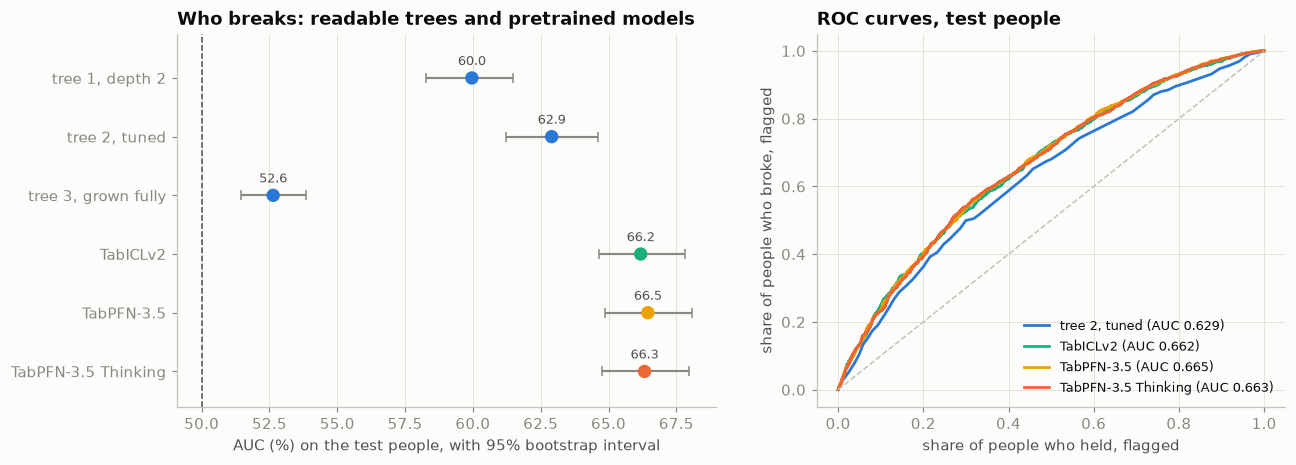

In [6]:
# who breaks: the three readable trees of notebook 04 against the pretrained models, on the same test people. AUC with a 95% interval
# from 2,000 bootstrap resamples of the test people; the difference to the tuned tree is paired (both scored on the same resample)
for nm, f in FM.items():                                                            # scores kept by cells 2-4, in this or another session
    fp = PROC / f"fm_{f}_test_scores.parquet"
    if nm not in P and fp.exists():
        d_ = pd.read_parquet(fp); assert (d_.y.to_numpy() == yte).all(), f"{fp.name} is from other test people"; P[nm] = d_.p.to_numpy()
trees = pd.read_parquet(PROC / "tree_test_scores.parquet")
assert len(trees) == len(yte) and (trees.y.to_numpy() == yte).all(), "tree scores and this table are not the same test people"
cut = ytr.mean()                          # pretrained models: 'broke' above the training share, the balance class weights give the trees at 0.5
models = {nm: (trees[nm].to_numpy(), 0.5) for nm in trees.columns if nm != "y"} | {nm: (P[nm], cut) for nm in FM if nm in P}
REF = "tree 2, tuned"
idx = np.random.default_rng(SEED).integers(0, len(yte), (2000, len(yte)))
boot = {nm: np.array([roc_auc_score(yte[i], p[i]) for i in idx]) for nm, (p, c) in models.items()}
rows = []
for nm, (p, c) in models.items():
    a, d = roc_auc_score(yte, p), boot[nm] - boot[REF]
    rows.append((nm, accuracy_score(yte, p > c), balanced_accuracy_score(yte, p > c), a, *np.percentile(boot[nm], [2.5, 97.5]),
                 a - roc_auc_score(yte, models[REF][0]), *np.percentile(d, [2.5, 97.5])))
res = pd.DataFrame(rows, columns=["model", "accuracy", "balanced accuracy", "AUC", "AUC 2.5%", "AUC 97.5%",
                                  "AUC minus tuned tree", "diff 2.5%", "diff 97.5%"]).set_index("model")
print(res.round(3).to_string()); print(f"always 'held': accuracy {1 - yte.mean():.3f}, balanced accuracy 0.5, AUC 0.5")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
yy = np.arange(len(res))[::-1]
col = [C[0] if nm.startswith("tree") else FMCOL[nm] for nm in res.index]
axes[0].errorbar(res.AUC * 100, yy, xerr=[(res.AUC - res["AUC 2.5%"]) * 100, (res["AUC 97.5%"] - res.AUC) * 100], fmt="none", ecolor="#898781", lw=1.4, capsize=3)
axes[0].scatter(res.AUC * 100, yy, color=col, s=60, zorder=3)
for v, y_ in zip(res.AUC, yy): axes[0].text(v * 100, y_ + 0.22, f"{v * 100:.1f}", ha="center", fontsize=8.5, color="#52514e")
axes[0].axvline(50, color="#52514e", ls="--", lw=1); axes[0].set_yticks(yy); axes[0].set_yticklabels(res.index); axes[0].yaxis.grid(False)
axes[0].set_ylim(-0.6, len(res) - 0.25)
axes[0].set(xlabel="AUC (%) on the test people, with 95% bootstrap interval", title="Who breaks: readable trees and pretrained models")
for nm, (p, c) in models.items():
    if nm.startswith("tree") and nm != REF: continue
    fpr, tpr, _ = roc_curve(yte, p)
    axes[1].plot(fpr, tpr, lw=1.8, color=C[0] if nm.startswith("tree") else FMCOL[nm], label=f"{nm} (AUC {roc_auc_score(yte, p):.3f})")
axes[1].plot([0, 1], [0, 1], color="#c3c2b7", ls="--", lw=1)
axes[1].set(xlabel="share of people who held, flagged", ylabel="share of people who broke, flagged", title="ROC curves, test people")
axes[1].legend(frameon=False, fontsize=8.5, loc="lower right")
save(fig, "f46_tabular_fm")
pd.DataFrame({"y": yte, **{nm: p for nm, (p, c) in models.items()}}).to_parquet(PROC / "who_breaks_test_scores.parquet")
log_now(who_breaks=res.round(4).to_dict(orient="index"), who_breaks_reference=REF, pretrained_threshold=round(float(cut), 4))

In [7]:
# one archive with what this notebook produced, to download from the file browser. Press Ctrl+S first, then run this cell again,
# so the archive holds the notebook with its outputs
import zipfile
print(json.dumps(LOG, indent=2, default=str))
out = ROOT / "part3_foundation_outputs.zip"
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(FIG.glob("f4[5-6]_*.png")):
        z.write(p, f"figures/{p.name}")
    for p in [LOGF, ROOT / "notebooks/05_foundation_models.ipynb"]:
        if p.exists(): z.write(p, str(p.relative_to(ROOT)))
        else: print("missing:", p)
print(out, f"{out.stat().st_size / 1e6:.1f} MB")

{
  "device": "cuda",
  "gpu": "NVIDIA L40",
  "packages": {
    "torch": "2.14.1+cu126",
    "chronos-forecasting": "2.3.2",
    "tabicl": "2.2.0",
    "tabpfn": "9.2.0",
    "tabpfn-client": "0.6.1",
    "scikit-learn": "1.9.0"
  },
  "chronos": {
    "seconds": 21.9,
    "day_auc_eval": 0.6008,
    "worse_in_emergency_share": 0.6786,
    "corr_with_surprise_rise": 0.5019,
    "agrees_with_label_auc": 0.7771,
    "median_score_by_kind": {
      "far roamers": 0.00175,
      "mid-range movers": 0.00406,
      "regular commuters": 0.01316,
      "local regulars": 0.00827,
      "weekend movers": 0.00887,
      "homebodies": 0.00184
    },
    "nb_and_chronos_day_auc": {
      "multinomial NB": 0.5384,
      "Bernoulli NB (when seen)": 0.5909,
      "where NB, everyone": 0.5318,
      "where NB, per kind": 0.5478,
      "where NB, per person": 0.5591,
      "Chronos-2, zero-shot": 0.6008
    }
  },
  "tabicl": {
    "test_auc": 0.6619,
    "seconds": 3.6,
    "device": "cuda"
  },
  "ta